# AI-Driven Pottery Classification

Binary image classifier that separates **handmade** pottery (label `0`) from **machine-made** ware (label `1`).

**Workflow**
1. Load and filter two public Hugging Face image datasets, then merge supplementary image archives.
2. Resize every image to 224×224 RGB and save the merged arrays as a compressed `.npz`.
3. Train a CNN from scratch (augmentation + focal loss) and a MobileNetV2 transfer-learning model.
4. Evaluate with classification reports and confusion matrices, and run the CNN on four external photos.

**Notes**
- Written for Google Colab (T4 GPU according to the notebook metadata). Code and saved outputs come from the original run; only markdown cells were added in this copy.
- The supplementary image archives, external test photos, merged dataset array and trained model are **not included** in this repository (see the README, *Required files*).
- Some code comments are in Arabic.

## 1. Environment: Google Drive
Mounts Google Drive so the notebook can read and write artifacts there. See the README (*Google Drive setup*) for how to point the notebook at your own files.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data loading and first filtering pass
Loads `eddie-cui/Pottery-Like` (handmade) and `groove-net/kitchenware_5000_split` (machine-made) from the Hugging Face Hub. Machine-made images are filtered to class IDs 0, 1 and 4 (bowl, cup, plate according to the notebook comments), giving 3,851 handmade and 69 machine-made images. This first pass is superseded by the next cell; its `X` and `y` arrays are not used later.

جاري تحميل البيانات... (قد يستغرق دقيقتين)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Resolving data files:   0%|          | 0/3852 [00:00<?, ?it/s]

بدء تنقية البيانات الآلية (استبعاد الملاعق والسكاكين)...


Processing Label 0:   0%|          | 0/3851 [00:00<?, ?it/s]

Processing Label 1:   0%|          | 0/69 [00:00<?, ?it/s]


✓ تم تجهيز البيانات بنجاح!
✓ عدد صور اليدوي: 3851
✓ عدد صور الآلي بعد التصفية: 69
✓ الإجمالي: 3920


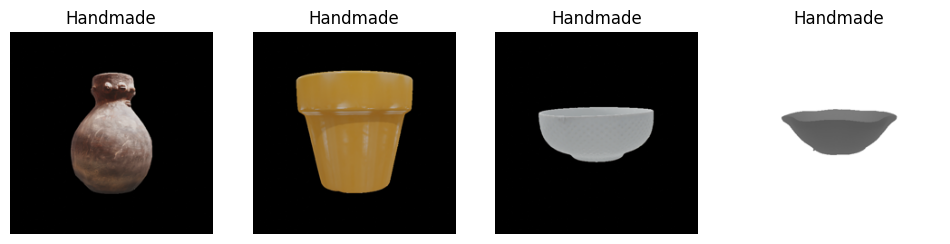

In [ ]:
# ==============================================
# 1. الاستيرادات وتجهيز البيئة
# ==============================================
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm # لشريط التحدم الاحترافي

# ==============================================
# 2. تحميل البيانات (Handmade & Machine-made)
# ==============================================
print("جاري تحميل البيانات... (قد يستغرق دقيقتين)")
handmade_ds = load_dataset("eddie-cui/Pottery-Like", split="train")
machine_ds = load_dataset("groove-net/kitchenware_5000_split", split="train")

# ==============================================
# 3. استراتيجية التنقية (Filtering Strategy)
# حسب متطلبات المشروع: نختار فقط الأكواب والأطباق
# ==============================================
# الأرقام في Dataset: 0=bowl, 1=cup, 4=plate
allowed_labels = [0, 1, 4]

print("بدء تنقية البيانات الآلية (استبعاد الملاعق والسكاكين)...")
machine_filtered = machine_ds.filter(lambda x: x['label'] in allowed_labels)

# ==============================================
# 4. المعالجة الموحدة (Processing)
# ==============================================
def process_images(dataset, label_value, limit=4000):
    images = []
    labels = []
    # نحدد ليميت حتى لا ينفجر الـ RAM في كولاب
    count = 0
    for item in tqdm(dataset, desc=f"Processing Label {label_value}"):
        if count >= limit: break
        try:
            # تحويل الصورة لمقاس 224x224 وتوحيد الألوان
            img = item['image'].convert('RGB').resize((224, 224))
            images.append(np.array(img))
            labels.append(label_value)
            count += 1
        except:
            continue
    return images, labels

# معالجة اليدوي (Label 0) والآلي (Label 1)
x_hand, y_hand = process_images(handmade_ds, 0)
x_mach, y_mach = process_images(machine_filtered, 1)

# دمج البيانات
X = np.array(x_hand + x_mach)
y = np.array(y_hand + y_mach)

# ==============================================
# 5. الإحصائيات (مهمة لتقرير Phase 1 & 2)
# ==============================================
print("\n" + "="*30)
print(f"✓ تم تجهيز البيانات بنجاح!")
print(f"✓ عدد صور اليدوي: {len(x_hand)}")
print(f"✓ عدد صور الآلي بعد التصفية: {len(x_mach)}")
print(f"✓ الإجمالي: {len(X)}")
print("="*30)

# عرض عينات عشوائية للتأكد
plt.figure(figsize=(12, 6))
for i in range(4):
    idx = np.random.randint(0, len(X))
    plt.subplot(1, 4, i+1)
    plt.imshow(X[idx])
    plt.title("Handmade" if y[idx]==0 else "Machine-made")
    plt.axis('off')
plt.show()


## 3. Expanded machine-made selection
Repeats the loading with class IDs 0, 1, 4, 5 and 6 to obtain more machine-made samples: 3,851 handmade + 522 machine-made = 4,373 images (`X_final`, `y_final`).

بدء تنقية البيانات الآلية (استبعاد الملاعق والسكاكين)...
جاري المعالجة... (هذه الخطوة أسرع)


Processing Label 0:   0%|          | 0/3851 [00:00<?, ?it/s]

Processing Label 1:   0%|          | 0/522 [00:00<?, ?it/s]


✅ مبروك! الأعداد النهائية الآن:
✓ Handmade (0): 3851
✓ Machine-made (1): 522
✓ إجمالي الصور للمشروع: 4373


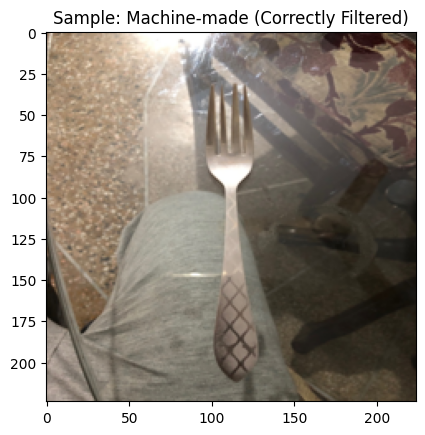

In [ ]:
# ==============================================
# خلية الإصلاح الشامل - تشغيل ذكي
# ==============================================
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm
import random

# التأكد من وجود البيانات في الذاكرة لتجنب إعادة التحميل الطويل
if 'handmade_ds' not in locals():
    print("جاري تحميل بيانات اليدوي (مرة واحدة فقط)...")
    handmade_ds = load_dataset("eddie-cui/Pottery-Like", split="train")

if 'machine_ds' not in locals():
    print("جاري تحميل بيانات الآلي (مرة واحدة فقط)...")
    machine_ds = load_dataset("groove-net/kitchenware_5000_split", split="train")

# 1. تحديث قائمة الفئات لزيادة العدد (أكواب، صحون، أواني، كاسات)
extended_labels = [0, 1, 4, 5, 6]

print("بدء تنقية البيانات الآلية (استبعاد الملاعق والسكاكين)...")
machine_filtered_v2 = machine_ds.filter(lambda x: x['label'] in extended_labels)

# 2. وظيفة المعالجة (تأكدي أن المقاس 224x224)
def fast_process(dataset, label_val):
    images, labels = [], []
    for item in tqdm(dataset, desc=f"Processing Label {label_val}"):
        try:
            img = item['image'].convert('RGB').resize((224, 224))
            images.append(np.array(img))
            labels.append(label_val)
        except: continue
    return images, labels

# معالجة البيانات
print("جاري المعالجة... (هذه الخطوة أسرع)")
x_hand, y_hand = fast_process(handmade_ds, 0)
x_mach, y_mach = fast_process(machine_filtered_v2, 1)

# 3. الدمج النهائي
X_final = np.array(x_hand + x_mach)
y_final = np.array(y_hand + y_mach)

print(f"\n✅ مبروك! الأعداد النهائية الآن:")
print(f"✓ Handmade (0): {len(x_hand)}")
print(f"✓ Machine-made (1): {len(x_mach)}")
print(f"✓ إجمالي الصور للمشروع: {len(X_final)}")

# عرض عينة عشوائية للتأكد من التصفية
plt.imshow(x_mach[random.randint(0, len(x_mach)-1)])
plt.title("Sample: Machine-made (Correctly Filtered)")
plt.show()



## 4. Supplementary image archives
Extracts three archives (`Handmade_New.zip`, `Machine_New.zip`, `Machine_New2.zip`) into `/content/final_dataset/`. These files must be present in the working directory; they are not part of this repository.

In [ ]:
import zipfile
import os
import shutil

zips_to_extract = [
    ('Handmade_New.zip', '/content/final_dataset/Handmade'),
    ('Machine_New.zip', '/content/final_dataset/Machine'),
    ('Machine_New2.zip', '/content/final_dataset/Machine')
]

for zip_path, target_folder in zips_to_extract:
    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(target_folder)
        print(f"✅ Extracted {zip_path} to {target_folder}")
    else:
        print(f"⚠️ Warning: {zip_path} not found!")

✅ Extracted Handmade_New.zip to /content/final_dataset/Handmade
✅ Extracted Machine_New.zip to /content/final_dataset/Machine
✅ Extracted Machine_New2.zip to /content/final_dataset/Machine


## 5. Merge supplementary images
Resizes the supplementary images to 224×224 RGB and merges them with the Hugging Face images (+50 handmade, +175 machine-made): **4,598 images in total** (3,901 handmade / 697 machine-made).

In [ ]:
import numpy as np
from PIL import Image
import os
import glob
from tqdm.auto import tqdm

# مصفوفات إضافية للصور الجديدة فقط
x_extra = []
y_extra = []

# تحديد المجلدات التي فككنا فيها الـ Zips
paths = {
    0: '/content/final_dataset/Handmade', # Label 0
    1: '/content/final_dataset/Machine'   # Label 1
}

for label, folder_path in paths.items():
    if os.path.exists(folder_path):
        image_files = []
        for ext in ['*.jpg', '*.png', '*.jpeg', '*.JPG', '*.PNG']:
            image_files.extend(glob.glob(os.path.join(folder_path, '**', ext), recursive=True))

        for img_path in tqdm(image_files, desc=f"Merging Label {label} Images"):
            try:
                img = Image.open(img_path).convert('RGB').resize((224, 224))
                x_extra.append(np.array(img))
                y_extra.append(label)
            except: continue

# الدمج النهائي مع المصفوفات الأصلية
if len(x_extra) > 0:
    X_total = np.concatenate([X_final, np.array(x_extra)], axis=0)
    y_total = np.concatenate([y_final, np.array(y_extra)], axis=0)
    print(f"\n✅ GREAT! Found and merged {len(x_extra)} new images.")
    print(f"📊 Total dataset size now: {len(X_total)}")
else:
    X_total, y_total = X_final, y_final
    print("\n❌ STILL NOT FOUND. Please check if the images are actually in /content/final_dataset")

Merging Label 0 Images:   0%|          | 0/50 [00:00<?, ?it/s]

Merging Label 1 Images:   0%|          | 0/175 [00:00<?, ?it/s]


✅ GREAT! Found and merged 225 new images.
📊 Total dataset size now: 4598


## 6. Save the merged dataset
Writes `pottery_data_full.npz` (arrays `x` and `y`). The MobileNetV2 section reads this file.

In [ ]:
import numpy as np
np.savez_compressed('pottery_data_full.npz', x=X_total, y=y_total)
print("✅ تم حفظ الملف الشامل بنجاح! الآن يمكنك إرساله للزميلات.")

✅ تم حفظ الملف الشامل بنجاح! الآن يمكنك إرساله للزميلات.


## 7. Model A: CNN trained from scratch
- **Split:** 80/20 `train_test_split` (`random_state=42`, not stratified): 3,678 training / 920 validation images.
- **Augmentation (training only):** rescale 1/255, rotation 40°, width/height shift 0.2, shear 0.2, zoom 0.2, horizontal flip.
- **Architecture:** 4 × [Conv2D (32, 64, 128, 256 filters, 3×3) → BatchNorm → MaxPool], Flatten, Dense(512) + BatchNorm + Dropout(0.5), Dense(1, sigmoid).
- **Training:** Adam (lr 1e-4), `BinaryFocalCrossentropy` (γ=2, α=0.25), 25 epochs, batch size 32.
- **Checkpointing:** `ModelCheckpoint` keeps the epoch with the best validation accuracy (0.9935 in the saved log). Validation accuracy fluctuates strongly between epochs in the saved log, so read the curves with that in mind.

🚀 [INFO] Training Advanced CNN with Focal Loss for Class Imbalance...
Epoch 1/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.7424 - loss: 0.3933
Epoch 1: val_accuracy improved from None to 0.47500, saving model to best_cnn_scratch_v4.keras

Epoch 1: finished saving model to best_cnn_scratch_v4.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 78s 561ms/step - accuracy: 0.8083 - loss: 0.2591 - val_accuracy: 0.4750 - val_loss: 0.2358
Epoch 2/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 452ms/step - accuracy: 0.8839 - loss: 0.1306
Epoch 2: val_accuracy improved from 0.47500 to 0.50000, saving model to best_cnn_scratch_v4.keras

Epoch 2: finished saving model to best_cnn_scratch_v4.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 55s 477ms/step - accuracy: 0.8855 - loss: 0.1315 - val_accuracy: 0.5000 - val_loss: 1.0367
Epoch 3/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.9043 - loss: 0.0980
Epoch 3: val_accuracy improved from 0.50000 to 0.50761, saving model to best_cnn_scratch_v4.keras

Epoch 3: fin

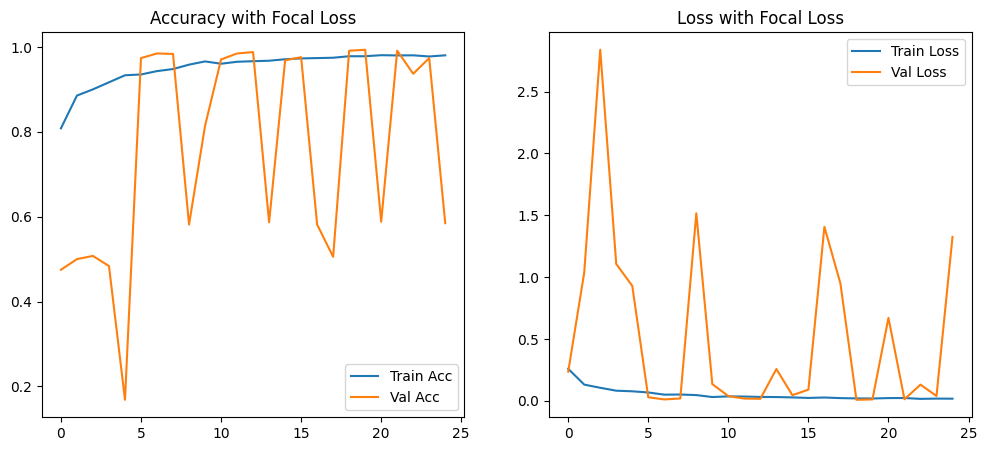


✅ [SUCCESS] Advanced CNN is ready and saved as: best_cnn_scratch_v4.keras


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. Splitting the data
X_train, X_val, y_train, y_val = train_test_split(X_total, y_total, test_size=0.2, random_state=42)

# 2. Advanced Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

# 3. Professional Deep CNN Architecture (From Scratch)
def build_advanced_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        # Block 1
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(), # Fixes Internal Covariate Shift
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Block 4
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Dense Layers
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5), # Strong Regularization
        layers.Dense(1, activation='sigmoid')
    ])
    return model

pottery_model = build_advanced_cnn()

# 4. Compilation with Binary Focal Crossentropy (Solving Imbalance)
pottery_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss=tf.keras.losses.BinaryFocalCrossentropy(gamma=2.0, alpha=0.25),
    metrics=['accuracy']
)

# 5. Training Callbacks
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_cnn_scratch_v4.keras',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max',
    verbose=1
)

# 6. Training Execution
print("🚀 [INFO] Training Advanced CNN with Focal Loss for Class Imbalance...")
history = pottery_model.fit(
    train_datagen.flow(X_train, y_train, batch_size=32),
    validation_data=val_datagen.flow(X_val, y_val, batch_size=32),
    epochs=25,
    callbacks=[checkpoint]
)

# 7. Visualization of Results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy with Focal Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss with Focal Loss')
plt.legend()
plt.show()

print("\n✅ [SUCCESS] Advanced CNN is ready and saved as: best_cnn_scratch_v4.keras")

## 8. Export the trained model
Downloads the best checkpoint (`best_cnn_scratch_v4.keras`) and copies it to Google Drive. The model file is not stored in this repository.

In [ ]:
from google.colab import files

files.download('best_cnn_scratch_v4.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
shutil.copy('best_cnn_scratch_v4.keras', '/content/drive/MyDrive/best_cnn_scratch_v4.keras')

'/content/drive/MyDrive/best_cnn_scratch_v4.keras'

## 9. Evaluation of the CNN
- Loads `best_cnn_scratch_v4.keras`.
- **External photos:** predicts four images that are not part of the dataset (`handmade.jpg`, `handmade1.jpg`, `Machinmade.jpg`, `Machinmade1.jpg`; not included). Saved outputs: Handmade 61.35%, Handmade 69.20%, Machine-made 99.63%, Machine-made 78.81%. This is a small qualitative check, not a benchmark.
- **Validation split:** confusion matrix and classification report on the 920-image validation split from the training cell (775 handmade / 145 machine-made); accuracy 0.99. The checkpoint was selected on this same split, so treat the figure as an optimistic estimate.
- Requires `X_val` / `y_val` from the CNN training cell.

🚀 Loading the best model...

--- Testing External Images ---
📸 Image: handmade.jpg | Prediction: Handmade (61.35%)
📸 Image: handmade1.jpg | Prediction: Handmade (69.20%)
📸 Image: Machinmade.jpg | Prediction: Machine-made (99.63%)
📸 Image: Machinmade1.jpg | Prediction: Machine-made (78.81%)

📊 Generating Confusion Matrix...
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step


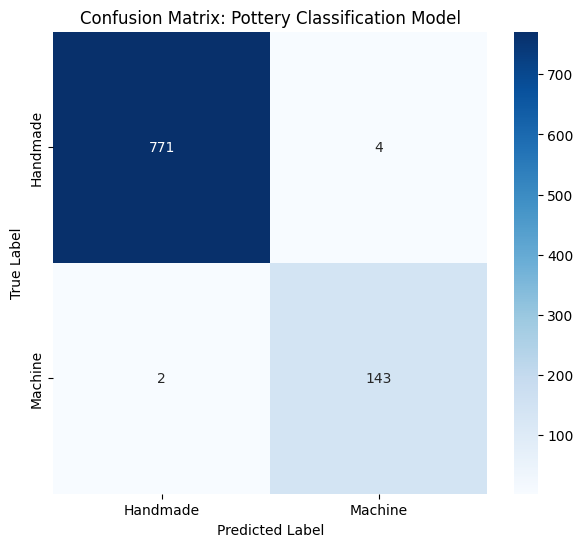


--- Detailed Classification Report ---
              precision    recall  f1-score   support

    Handmade       1.00      0.99      1.00       775
     Machine       0.97      0.99      0.98       145

    accuracy                           0.99       920
   macro avg       0.99      0.99      0.99       920
weighted avg       0.99      0.99      0.99       920



In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. دالة التنبؤ الفردي
def predict_pottery(img_path, model):
    try:
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array, verbose=0)[0][0]
        result = "Machine-made" if prediction > 0.5 else "Handmade"
        confidence = prediction if prediction > 0.5 else (1 - prediction)

        print(f"📸 Image: {img_path} | Prediction: {result} ({confidence*100:.2f}%)")
    except Exception as e:
        print(f"❌ Could not predict image {img_path}: {e}")

print("🚀 Loading the best model...")
final_model = tf.keras.models.load_model('best_cnn_scratch_v4.keras')

# 2. تشغيل التنبؤ على صور الخارجية
print("\n--- Testing External Images ---")
external_images = ['handmade.jpg', 'handmade1.jpg', 'Machinmade.jpg', 'Machinmade1.jpg']
for img in external_images:
    predict_pottery(img, final_model)

# 3. حساب ورسم مصفوفة الارتباك (Confusion Matrix)
print("\n📊 Generating Confusion Matrix...")
y_pred_probs = final_model.predict(X_val / 255.0) # نقسم على 255 للمعالجة
y_pred = (y_pred_probs > 0.5).astype("int32")

# حساب المصفوفة
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Handmade', 'Machine'],
            yticklabels=['Handmade', 'Machine'])
plt.title('Confusion Matrix: Pottery Classification Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 4. طباعة تقرير التصنيف التفصيلي
print("\n--- Detailed Classification Report ---")
print(classification_report(y_val, y_pred, target_names=['Handmade', 'Machine']))

## 10. Visual check on external photos
Displays each external photo with the CNN's predicted class and confidence.

🔄 Loading model from file...

--- Visualizing External Image Predictions ---


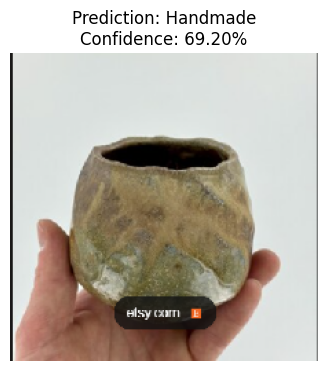

✅ Prediction completed for: handmade.jpg


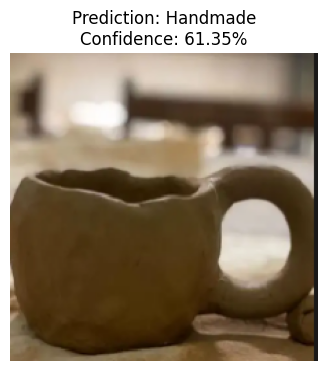

✅ Prediction completed for: handmade1.jpg


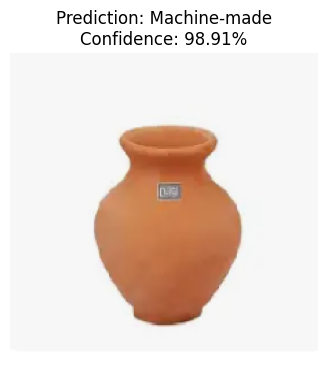

✅ Prediction completed for: Machinmade.jpg


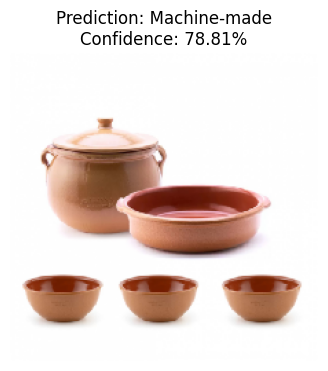

✅ Prediction completed for: Machinmade1.jpg


In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image

# 1. تحميل الموديل أولاً
print("🔄 Loading model from file...")
final_model = tf.keras.models.load_model('best_cnn_scratch_v4.keras')

# 2. الدالة المعدلة لعرض الصورة مع التنبؤ
def predict_and_show_pottery(img_path, model):
    try:
        # تحميل ومعالجة الصورة للتنبؤ
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img) / 255.0
        img_array_expanded = np.expand_dims(img_array, axis=0)

        # التنبؤ
        prediction = model.predict(img_array_expanded, verbose=0)[0][0]

        # تحديد النتيجة بناءً على التدريب  (0 للهاند ميد و 1 للمشين)
        result = "Machine-made" if prediction > 0.5 else "Handmade"
        confidence = prediction if prediction > 0.5 else (1 - prediction)


        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(f"Prediction: {result}\nConfidence: {confidence*100:.2f}%")
        plt.axis('off')
        plt.show()

        print(f"✅ Prediction completed for: {img_path}")

    except Exception as e:
        print(f"❌ Error with image {img_path}: {e}")

# 3. تشغيل التنبؤ على الصور الخارجية
print("\n--- Visualizing External Image Predictions ---")
external_images = ['handmade.jpg', 'handmade1.jpg', 'Machinmade.jpg', 'Machinmade1.jpg']

for img in external_images:
    predict_and_show_pottery(img, final_model)

## 11. Model B: MobileNetV2 transfer learning
- Loads `pottery_data_full.npz` (4,598 images).
- Balances the classes by sampling 1,000 handmade images (seed 42) and keeping all 697 machine-made images: 1,697 images.
- Scales pixels to [0, 1] and makes a stratified 80/20 split: 1,357 training / 340 test images.
- **Model:** MobileNetV2 (ImageNet weights, frozen) → GlobalAveragePooling2D → Dense(1, sigmoid). Adam, binary cross-entropy, 5 epochs, batch size 16, `validation_split=0.1`.
- **Saved result on the 340-image test set:** accuracy 0.9912; confusion matrix [[198, 2], [1, 139]].
- **Limitation:** handmade and machine-made images come from different source datasets, so the score may partly reflect differences between datasets rather than craftsmanship alone.

✅ إجمالي الصور: 4598
Handmade (0): 3901
Machine-made (1): 697

📊 بعد التوازن:
Handmade: 1000
Machine-made: 697
الإجمالي: 1697

🚀 جاري التدريب...
Epoch 1/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 29s 282ms/step - accuracy: 0.9361 - loss: 0.2139 - val_accuracy: 0.9706 - val_loss: 0.1040
Epoch 2/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9910 - loss: 0.0643 - val_accuracy: 0.9779 - val_loss: 0.0741
Epoch 3/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9943 - loss: 0.0414 - val_accuracy: 0.9853 - val_loss: 0.0619
Epoch 4/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9975 - loss: 0.0299 - val_accuracy: 0.9853 - val_loss: 0.0565
Epoch 5/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9984 - loss: 0.0229 - val_accuracy: 0.9779 - val_loss: 0.0556
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step

🎯 Accuracy: 0.9912 (99.12%)

📋 Classification Report:
              precision    recall  f1-score   support

    Handmade       0.99      0.99      0.99       200
Machine-made       0

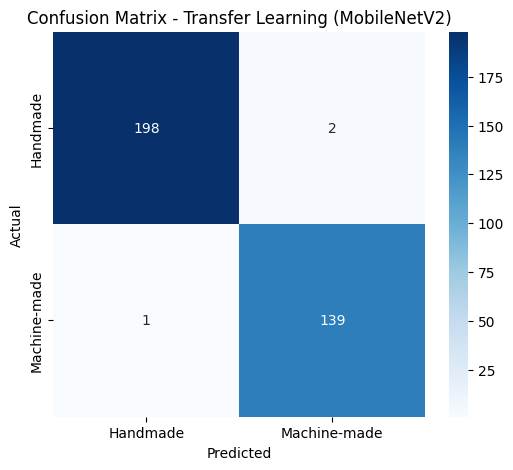

In [ ]:
# ==========================================
# TRANSFER LEARNING - إصدار متوازن
# ==========================================

import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. تحميل البيانات كاملة
data = np.load('pottery_data_full.npz')
X = data['x']
y = data['y']

print(f"✅ إجمالي الصور: {X.shape[0]}")
print(f"Handmade (0): {np.sum(y==0)}")
print(f"Machine-made (1): {np.sum(y==1)}")

# 2. أخذ عينة متوازنة (1000 Handmade + كل Machine-made المتاح)
handmade_idx = np.where(y == 0)[0]
machine_idx = np.where(y == 1)[0]

# خذ 1000 من Handmade فقط عشان نتجنب الـ imbalance
np.random.seed(42)
handmade_sample = np.random.choice(handmade_idx, size=min(1000, len(handmade_idx)), replace=False)

# خذ كل الـ Machine-made
selected_idx = np.concatenate([handmade_sample, machine_idx])
X_balanced = X[selected_idx]
y_balanced = y[selected_idx]

# خلط البيانات
shuffle_idx = np.random.permutation(len(X_balanced))
X_balanced = X_balanced[shuffle_idx]
y_balanced = y_balanced[shuffle_idx]

print(f"\n📊 بعد التوازن:")
print(f"Handmade: {np.sum(y_balanced==0)}")
print(f"Machine-made: {np.sum(y_balanced==1)}")
print(f"الإجمالي: {len(X_balanced)}")

# 3. تطبيع
X_balanced = X_balanced / 255.0

# 4. تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced)

# 5. نموذج MobileNetV2
base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))
base.trainable = False

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("\n🚀 جاري التدريب...")
model.fit(X_train, y_train, validation_split=0.1, epochs=5, batch_size=16, verbose=1)

# 6. التقييم
y_pred = (model.predict(X_test) > 0.5).astype(int)
acc = np.mean(y_pred.flatten() == y_test)
print(f"\n🎯 Accuracy: {acc:.4f} ({acc*100:.2f}%)")

print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Handmade', 'Machine-made']))

# 7. Confusion Matrix
plt.figure(figsize=(6,5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Handmade', 'Machine-made'],
            yticklabels=['Handmade', 'Machine-made'])
plt.title('Confusion Matrix - Transfer Learning (MobileNetV2)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()